<img width=600 height=300 src="https://imgs.xkcd.com/comics/sustainable.png"/>

In [1]:
# special IPython command to prepare the notebook for matplotlib
%matplotlib inline 

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt

import seaborn as sns
sns.set_style("whitegrid")
sns.set_context("poster")

# special matplotlib argument for improved plots
from matplotlib import rcParams


# Logistic Regression



<div class="span5 alert alert-info">
<p>Logistic regression is a probabilistic model that links observed binary data to a set of features.</p>

<p>Suppose that we have a set of binary (that is, taking the values 0 or 1) observations Y<sub>1</sub>....Y<sub>n</sub>, and for each observation Y<sub>i</sub> we have a vector of features X<sub>i</sub>. The logistic regression model assumes that there is some set of <b>weights</b>, <b>coefficients</b>, or <b>parameters</b> &#946;.
<br>
<p>When we <b>fit</b> a logistic regression model, we determine values for each &#946; that allows the model to best fit the <b>training data</b> we have observed. Once we do this, we can use these coefficients to make predictions about data we have not yet observed.</p>

</div>

From http://www.edwardtufte.com/tufte/ebooks, in "Visual and Statistical Thinking: 
Displays of Evidence for Making Decisions":

>On January 28, 1986, the space shuttle Challenger exploded and seven astronauts died because two rubber O-rings leaked. These rings had lost their resiliency because the shuttle was launched on a very cold day. Ambient temperatures were in the low 30s and the O-rings themselves were much colder, less than 20F.

>One day before the flight, the predicted temperature for the launch was 26F to 29F. Concerned that the rings would not seal at such a cold temperature, the engineers who designed the rocket opposed launching Challenger the next day.

But they did not make their case persuasively, and were over-ruled by NASA.

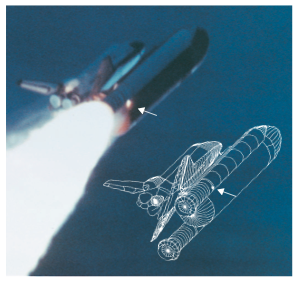

In [2]:
from IPython.display import Image as Im
from IPython.display import display
Im('./shuttle.png')

The image above shows the leak, where the O-ring failed.

We have here data on previous failures of the O-rings at various temperatures.

the array shows the temperature and the probability of ring failure. 

In [3]:
data=np.array([[float(j) for j in e.strip().split()] for e in open("chall.txt")])
data

array([[66.,  0.],
       [70.,  1.],
       [69.,  0.],
       [68.,  0.],
       [67.,  0.],
       [72.,  0.],
       [73.,  0.],
       [70.,  0.],
       [57.,  1.],
       [63.,  1.],
       [70.,  1.],
       [78.,  0.],
       [67.,  0.],
       [53.,  1.],
       [67.,  0.],
       [75.,  0.],
       [70.,  0.],
       [81.,  0.],
       [76.,  0.],
       [79.,  0.],
       [75.,  1.],
       [76.,  0.],
       [58.,  1.]])

Lets plot this data

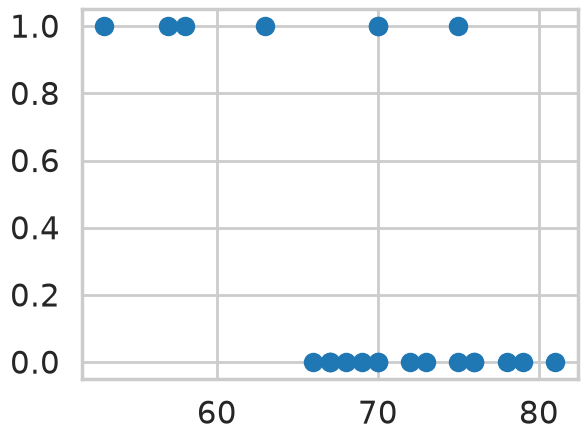

In [4]:
dat = pd.DataFrame(data, columns = ['Temp', 'Failure'])
plt.scatter(dat["Temp"],dat["Failure"])

Let's use Scikit Learn

https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

In [5]:
from sklearn.linear_model import LogisticRegression

In [6]:
# https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
model = LogisticRegression()

In [7]:
X = dat["Temp"].values
y = dat["Failure"].values
y

array([0., 1., 0., 0., 0., 0., 0., 0., 1., 1., 1., 0., 0., 1., 0., 0., 0.,
       0., 0., 0., 1., 0., 1.])

In [8]:
# reshape data to a 2d array for sklearn
model.fit(X.reshape(-1,1),y)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [9]:
# model needs 2d array for X 
model.score(X.reshape(-1,1),y)

0.8695652173913043

In [10]:
model.intercept_

array([14.86182022])

In [11]:
model.coef_

array([[-0.22949881]])

In [12]:
# create  1000 points between 50 and 85 in a straight line. 
x = np.linspace(50, 85, 1000)
# predict for these values the outome of the mdoel .
y_pred = model.predict(x.reshape(-1,1))

In [13]:
y_pred

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1.

(-0.1, 1.1)

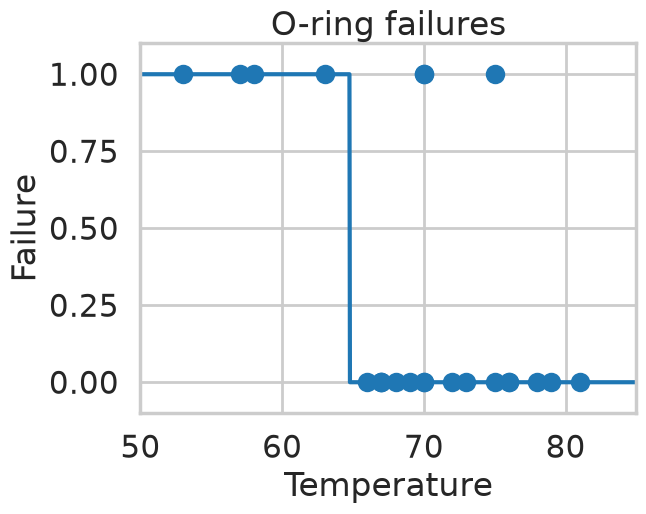

In [14]:
# plot in a scatter plot the data + the prediciton with lineplot. 
temps, pfail = data[:,0], data[:,1]
plt.scatter(temps, pfail)
# get current axes https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.gca.html 
axes=plt.gca()
plt.xlabel('Temperature')
plt.ylabel('Failure')
plt.title('O-ring failures')

# plot fitted values
plt.plot(x, y_pred)

# change limits, for a nicer plot
# set limits of the axes https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.xlim.html 
plt.xlim(50, 85)
plt.ylim(-0.1, 1.1)

#Square wave transition from success to failure (I'd prefer to see probabilities)

In [15]:
# get the probabiliyt of the prediction and not the outcome of the prediction. 2 info: probabiliyt, prediction. 
y_predprob = model.predict_proba(x.reshape(-1,1))
y_predprob

array([[0.03270804, 0.96729196],
       [0.03296338, 0.96703662],
       [0.03322065, 0.96677935],
       ...,
       [0.99033467, 0.00966533],
       [0.99041133, 0.00958867],
       [0.99048739, 0.00951261]], shape=(1000, 2))

(-0.1, 1.1)

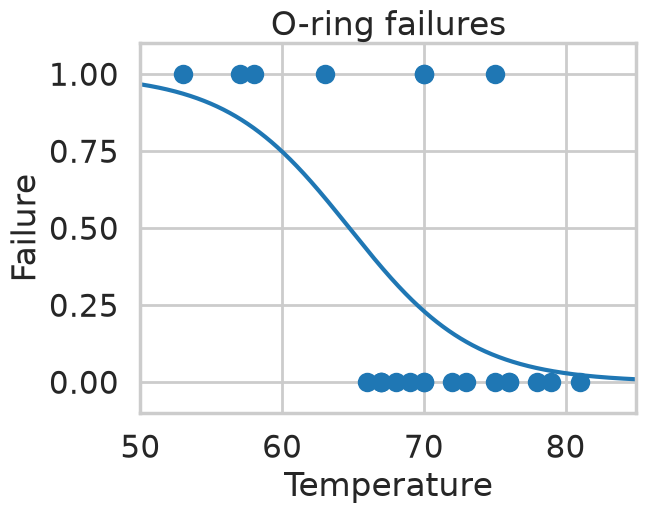

In [16]:
# plot the probability, not the prediction. it's never entirely 0 or 1, but a probability between 0 and 1.
temps, pfail = data[:,0], data[:,1]
plt.scatter(temps, pfail)
axes=plt.gca()
plt.xlabel('Temperature')
plt.ylabel('Failure')
plt.title('O-ring failures')

# plot fitted values
plt.plot(x, y_predprob[:,1])    #y_predprob has both probability and (1-y_predprob) - so we only plot column [:,1]

# change limits, for a nicer plot
plt.xlim(50, 85)
plt.ylim(-0.1, 1.1)


# Logistic Regression: Multiple independent variables

Logistic Regression Assumptions

    Binary logistic regression requires the dependent variable to be binary.
    For a binary regression, the dependent variable should represent the desired outcome.
    Only the meaningful variables should be included.
    The independent variables should be independent of each other. That is, the model should have little or no multicollinearity. (becaise high correlation affects stability and predictability)
    Logistic regression requires quite large sample sizes.

We will be using the Titanic dataset from kaggle, which is a collection of data points, including the age, gender, ticket price, etc.., of all the passengers aboard the Titanic. The data set has 891 rows and 12 columns. The goal is to see if we can predict whether any given passenger will die or survive. Hopefully you can see why logistic regression is a fitting model for this problem.

### Task 1
Read in the data as usual and view the first 5 terms, try to understand the contents of each column - think about which columns may be useful and which may not be useful.

In [17]:
df = pd.read_csv("titanic_dataset.csv")

In [18]:
# sibling or spouse aboard, parent or child aboard, fare, embarked
df.head()

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked
0,1,1,"Cornell, Mrs. Robert Clifford (Malvina Helen L...",female,55.0,2,0,11770,25.7000,C101,S
1,1,1,"Leader, Dr. Alice (Farnham)",female,49.0,0,0,17465,25.9292,D17,S
2,1,1,"Swift, Mrs. Frederick Joel (Margaret Welles Ba...",female,48.0,0,0,17466,25.9292,D17,S
3,1,1,"Newsom, Miss. Helen Monypeny",female,19.0,0,2,11752,26.2833,D47,S
4,1,1,"Bonnell, Miss. Elizabeth",female,58.0,0,0,113783,26.5500,C103,S


In [19]:
df.describe()

,pclass,survived,age,sibsp,parch,fare
count,1309.000000,1309.000000,1046.000000,1309.000000,1309.000000,1309.000000
mean,2.294882,0.381971,29.881135,0.498854,0.385027,33.275811
std,0.837836,0.486055,14.413500,1.041658,0.865560,51.743772
min,1.000000,0.000000,0.166700,0.000000,0.000000,0.000000
25%,2.000000,0.000000,21.000000,0.000000,0.000000,7.895800
50%,3.000000,0.000000,28.000000,0.000000,0.000000,14.454200
75%,3.000000,1.000000,39.000000,1.000000,0.000000,31.275000
max,3.000000,1.000000,80.000000,8.000000,9.000000,512.329200


In [20]:
df.isnull().sum()

pclass         0
survived       0
name           0
sex            0
age          263
sibsp          0
parch          0
ticket         0
fare           0
cabin       1014
embarked       0
dtype: int64

### Task 2
The Columns passengerID, Name and ticket probably are not going to affect a person's chance of survival. Additionally the column cabin has a lot of null values so we won't include that.

The column Age also has Null values, for this column we will just replace them with either the mean or the median

The column survived is going to be our dependent variable, it's either 1 or 0. 

Create the X and y variables that we will be using

In [21]:
# fill in blanks with median value of the column. This is a common way to deal with missing data.
df['age'] = df['age'].fillna(df['age'].median())

In [22]:
# select the columsn that you think are meaningful for the prediction of survival. You can add or remove columns as you see fit.
y = df["survived"]
X = df[["pclass","age","sex","sibsp","parch","fare","embarked"]]

In [23]:
X.head()

,pclass,age,sex,sibsp,parch,fare,embarked
0,1,55.0,female,2,0,25.7000,S
1,1,49.0,female,0,0,25.9292,S
2,1,48.0,female,0,0,25.9292,S
3,1,19.0,female,0,2,26.2833,S
4,1,58.0,female,0,0,26.5500,S


The sex column is categorical so we need to do some preprocessing to convert it

As long as you have X built correctly the following will encode the data, i.e. make male/female 1 and 0 (or 0 and 1) respectively

In [24]:
from sklearn import preprocessing
le_sex = preprocessing.LabelEncoder()
le_sex.fit(X['sex'])
sex = le_sex.transform(X['sex'])
X = X.drop(['sex'], axis = 1)
X['sex'] = sex
X

,pclass,age,sibsp,parch,fare,embarked,sex
0,1,55.0,2,0,25.7000,S,0
1,1,49.0,0,0,25.9292,S,0
2,1,48.0,0,0,25.9292,S,0
3,1,19.0,0,2,26.2833,S,0
4,1,58.0,0,0,26.5500,S,0
...,...,...,...,...,...,...,...
1304,3,14.5,8,2,69.5500,S,1
1305,3,28.0,8,2,69.5500,S,1
1306,3,28.0,8,2,69.5500,S,1
1307,3,28.0,8,2,69.5500,S,1


You need to do the similar thing for the column <b>Embarked</b>

First let's remove the nan entries

In [25]:
X["embarked"].unique()

<StringArray>
['S', 'C', 'Q']
Length: 3, dtype: str

There are 3 options here. LabelEncoder would give a ranking to each of them 0, 1, 2 based on alphabetical order

We probably don't want this. It does not always make sense to assign numbers. important to understand that numbers will affect the values of the sums / equation. 

We could use OneHotEncoder() this time to make things better, but for now, just use LabelEncoder

read <a href="https://www.analyticsvidhya.com/blog/2020/03/one-hot-encoding-vs-label-encoding-using-scikit-learn/">This Article</a> to see more

One-Hot Encoding is the process of creating dummy variables.

In [26]:
X["embarked"].values.reshape(-1,1)

<StringArray>
[
['S'],
['S'],
['S'],
['S'],
['S'],
['S'],
['S'],
['C'],
['C'],
['C'],
['C'],
['C'],
['C'],
['S'],
['C'],
['C'],
['S'],
['S'],
['S'],
['C'],
['C'],
['C'],
['S'],
['S'],
['S'],
['S'],
['S'],
['S'],
['S'],
['S'],
['S'],
['S'],
['S'],
['S'],
['S'],
['C'],
['C'],
['S'],
['C'],
['S'],
['C'],
['C'],
['C'],
['C'],
['C'],
['C'],
['S'],
['S'],
['C'],
['C'],
['S'],
['C'],
['C'],
['S'],
['C'],
['C'],
['C'],
['C'],
['C'],
['S'],
['S'],
['S'],
['C'],
['C'],
['S'],
['S'],
['C'],
['C'],
['S'],
['S'],
['S'],
['S'],
['S'],
['C'],
['S'],
['C'],
['C'],
['C'],
['C'],
['C'],
['S'],
['S'],
['S'],
['S'],
['C'],
['S'],
['Q'],
['Q'],
['C'],
['S'],
['S'],
['C'],
['C'],
['C'],
['C'],
['C'],
['C'],
['C'],
['C'],
['S'],
['S'],
['S'],
['C'],
['C'],
['C'],
['S'],
['C'],
['C'],
['C'],
['C'],
['C'],
['S'],
['S'],
['S'],
['S'],
['S'],
['S'],
['S'],
['S'],
['S'],
['S'],
['S'],
['S'],
['S'],
['C'],
['C'],
['S'],
['S'],
['C'],
['C'],
['C'],
['C'],
['C'],
['C'],
['C'],
['C'],
['C'],
['C'],
['S'],
['S'],
['S'

I've included this example of OneHotEncoder but have commented it out

### Start of onehotencoder

In [27]:
"""le_embark = preprocessing.OneHotEncoder(sparse=False)
le_embark.fit(X["embarked"].values.reshape(-1,1))
embarked = le_embark.transform(X["embarked"].values.reshape(-1,1))"""

'le_embark = preprocessing.OneHotEncoder(sparse=False)\nle_embark.fit(X["embarked"].values.reshape(-1,1))\nembarked = le_embark.transform(X["embarked"].values.reshape(-1,1))'

In [28]:
#embarked.shape

3 variables, one for each S, C, Q

Get rid of the original Embarked

In [29]:
"""X = X.drop(["embarked"], axis = 1)"""

'X = X.drop(["embarked"], axis = 1)'

Now put in the new columns

There's probably a better way but this will work

In [30]:
"""X["embarkC"] = embarked[:,0]
X["embarkQ"] = embarked[:,1]
X["embarkS"] = embarked[:,2]"""

'X["embarkC"] = embarked[:,0]\nX["embarkQ"] = embarked[:,1]\nX["embarkS"] = embarked[:,2]'

In [31]:
#X

### End of OneHotEncoder

It's not advised to do a LabelEncoder for this type of data, but it might do ok, and we'll use it now for simplicity

In [32]:
le_embark = preprocessing.LabelEncoder()
le_embark.fit(X["embarked"])
embarked = le_embark.transform(X["embarked"])
X = X.drop(["embarked"], axis = 1)
X["embarked"] = embarked
X

,pclass,age,sibsp,parch,fare,sex,embarked
0,1,55.0,2,0,25.7000,0,2
1,1,49.0,0,0,25.9292,0,2
2,1,48.0,0,0,25.9292,0,2
3,1,19.0,0,2,26.2833,0,2
4,1,58.0,0,0,26.5500,0,2
...,...,...,...,...,...,...,...
1304,3,14.5,8,2,69.5500,1,2
1305,3,28.0,8,2,69.5500,1,2
1306,3,28.0,8,2,69.5500,1,2
1307,3,28.0,8,2,69.5500,1,2


### Task 3
Do a train_test_split and build the model using sklearn

In [33]:
# set 25% as test set and the rest 75% as training set. The random_state is a seed for the random number generator, so that you can get the same split every time you run this code.
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

In [34]:
titanic_lm = LogisticRegression

In [ ]:
# set max number of iterations to 1000, so that the model has enough time to converge. The default is 100, which is sometimes not enough.
titanic_lm = LogisticRegression(max_iter=1000)

In [36]:
titanic_lm.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [37]:
y_train_predicted = titanic_lm.predict(X_train)
y_train_predprob = titanic_lm.predict_proba(X_train)

In [38]:
titanic_lm.score(X_train,y_train)

0.7981651376146789

We get a score of 80% accurate in predicting whether someone survives or not

However, this is on the training set, we really should use a different set to score our model, one that it has not seen before

Make sure you keep your titanic_lm model, do not overwrite it in the next task

### Task 4 
Let's use the model to make predictions with new information

In [39]:
y_test_predicted = titanic_lm.predict(X_test)
y_test_predprob = titanic_lm.predict_proba(X_test)

In [40]:
titanic_lm.score(X_test, y_test)

0.7957317073170732

score is similar to training set --> good, model is not overfitted. 

### Task 5: Join new predictions and probabilities into original dataset

In [41]:
y_predicted = titanic_lm.predict(X)
y_predprob = titanic_lm.predict_proba(X)

In [42]:
# create a new column in the dataframe with the predicted values and the probability of survival.
df['survive_predicted'] = y_predicted
df['survive_probability'] = y_predprob[:,1]

In [43]:
df

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,survive_predicted,survive_probability
0,1,1,"Cornell, Mrs. Robert Clifford (Malvina Helen L...",female,55.0,2,0,11770,25.7000,C101,S,1,0.707726
1,1,1,"Leader, Dr. Alice (Farnham)",female,49.0,0,0,17465,25.9292,D17,S,1,0.837260
2,1,1,"Swift, Mrs. Frederick Joel (Margaret Welles Ba...",female,48.0,0,0,17466,25.9292,D17,S,1,0.841580
3,1,1,"Newsom, Miss. Helen Monypeny",female,19.0,0,2,11752,26.2833,D47,S,1,0.920694
4,1,1,"Bonnell, Miss. Elizabeth",female,58.0,0,0,113783,26.5500,C103,S,1,0.794146
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1304,3,0,"Sage, Master. William Henry",male,14.5,8,2,CA. 2343,69.5500,NaN,S,0,0.015692
1305,3,0,"Sage, Mr. Douglas Bullen",male,28.0,8,2,CA. 2343,69.5500,NaN,S,0,0.010237
1306,3,0,"Sage, Mr. Frederick",male,28.0,8,2,CA. 2343,69.5500,NaN,S,0,0.010237
1307,3,0,"Sage, Mr. George John Jr",male,28.0,8,2,CA. 2343,69.5500,NaN,S,0,0.010237


We can see what our model predicts for the new data, additionally we've added in the probabilities for more information

Like age seems related to survival chance, also having dependants (childern, parents, spouse, siblings) lowers survival chance. 

You can make inference on how the factors affect the prediction. 